<a href="https://colab.research.google.com/github/An-n-nie/Fish_Biomass/blob/main/tabular/DataProblems_Project1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Loading Dataset

In [ ]:
import pandas as pd

df = pd.read_csv("/content/fish_data.csv")
df.shape

(2431, 30)

In [ ]:
!ls

fish_data.csv  sample_data


In [ ]:
!unzip archive.zip

unzip:  cannot find or open archive.zip, archive.zip.zip or archive.zip.ZIP.


In [ ]:
df.shape

(2431, 30)

In [ ]:
info_df = pd.DataFrame({
    "Column": df.columns,
    "Non-Null Count": df.notnull().sum(),
    "Null Count": df.isnull().sum(),
    "Data Type": df.dtypes
})

info_df

,Column,Non-Null Count,Null Count,Data Type
label,label,2431,0,object
year,year,2431,0,int64
month,month,2431,0,int64
day,day,2431,0,int64
region,region,2431,0,object
island,island,2431,0,object
side,side,2431,0,object
id_reef,id_reef,2431,0,int64
reef,reef,2431,0,object
reef_joined,reef_joined,2431,0,int64


In [ ]:
df.describe()

,year,month,day,id_reef,reef_joined,latitude,longitude,transect,area,trophic_level,a_ord,b_pen,quantity,size,biomass
count,2431.0,2431.0,2431.000000,2431.000000,2431.000000,2431.000000,2431.000000,2431.000000,2431.0,2431.000000,2431.000000,2431.000000,2431.000000,2431.000000,2431.000000
mean,2019.0,8.0,8.950638,7.746195,5.250103,22.783395,-89.364421,3.252571,60.0,2.902012,0.023805,2.960042,7.159194,11.125874,0.025772
std,0.0,0.0,1.395772,4.313554,2.607834,0.357746,0.466974,1.544261,0.0,0.761484,0.025825,0.203313,31.792145,9.064095,0.086340
min,2019.0,8.0,7.000000,1.000000,1.000000,22.384533,-89.796617,1.000000,60.0,2.000000,0.001000,2.230000,1.000000,1.000000,0.000000
25%,2019.0,8.0,8.000000,4.000000,3.000000,22.505367,-89.779633,2.000000,60.0,2.000000,0.014800,2.871000,1.000000,5.000000,0.001000
50%,2019.0,8.0,9.000000,8.000000,5.000000,22.567701,-89.654101,3.000000,60.0,3.110000,0.018200,3.000000,2.000000,8.000000,0.004300
75%,2019.0,8.0,10.000000,12.000000,8.000000,23.242417,-88.714417,4.000000,60.0,3.500000,0.027700,3.052000,5.000000,15.000000,0.019850
max,2019.0,8.0,11.000000,15.000000,10.000000,23.261683,-88.695417,6.000000,60.0,4.510000,0.532000,3.693000,800.000000,100.000000,2.269500


In [ ]:
df.isnull().sum()

,0
label,0
year,0
month,0
day,0
region,0
island,0
side,0
id_reef,0
reef,0
reef_joined,0


In [ ]:
df.isnull().sum().sum()

np.int64(0)

#### There are no missing values in this dataset, so no missing value imputation will be necessary.

In [ ]:
df.duplicated().sum()

np.int64(0)

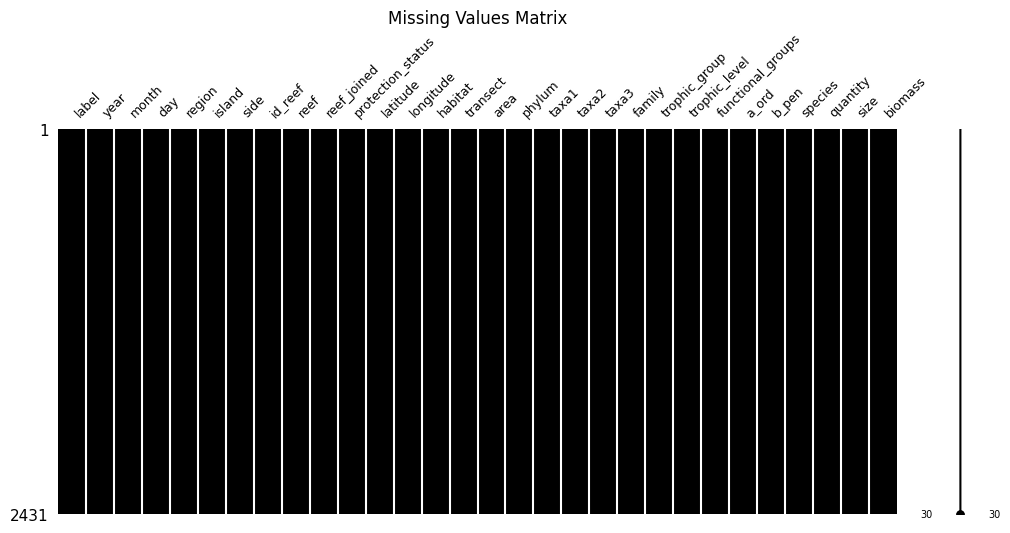

In [ ]:
import missingno as msno
import matplotlib.pyplot as plt

# Set color to black
ax = msno.matrix(df, figsize=(12, 5), fontsize=9, color=(0, 0, 0))
ax.set_title("Missing Values Matrix")
plt.show()

In [ ]:
column_types = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes,
    "Variable Type": [
        "Numerical" if pd.api.types.is_numeric_dtype(df[col])
        else "Categorical"
        for col in df.columns
    ]
})

column_types

,Column,Data Type,Variable Type
label,label,object,Categorical
year,year,int64,Numerical
month,month,int64,Numerical
day,day,int64,Numerical
region,region,object,Categorical
island,island,object,Categorical
side,side,object,Categorical
id_reef,id_reef,int64,Numerical
reef,reef,object,Categorical
reef_joined,reef_joined,int64,Numerical


#### The code block above checks if there are any duplicate observations, and there were none found.

In [ ]:
df["biomass"].describe()

,biomass
count,2431.000000
mean,0.025772
std,0.086340
min,0.000000
25%,0.001000
50%,0.004300
75%,0.019850
max,2.269500


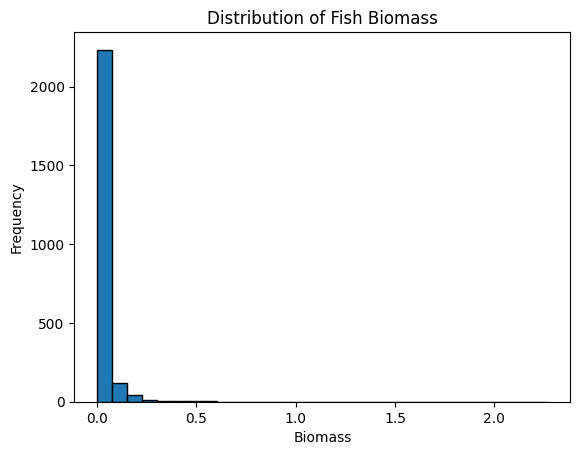

In [ ]:
import matplotlib.pyplot as plt

plt.hist(df["biomass"], bins=30, edgecolor="black")
plt.xlabel("Biomass")
plt.ylabel("Frequency")
plt.title("Distribution of Fish Biomass")
plt.show()

#### The histogram above shows the distribution of the target variable, biomass. The distribution is extremely right-skewed, meaning most observations have relatively low biomass values while a small number have much larger values. This skewness may influence regression performance, so it was considered when selecting and evaluating the models.

#### Although biomass is strongly right-skewed, we decided to keep the target variable on its original scale. The main models used in this project, including Random Forest, Gradient Boosting, and XGBoost, can model nonlinear relationships without requiring the target variable to be normally distributed. Keeping biomass in its original units also makes MAE and RMSE easier to interpret. A log transformation could be explored in future work to determine whether it improves model performance.

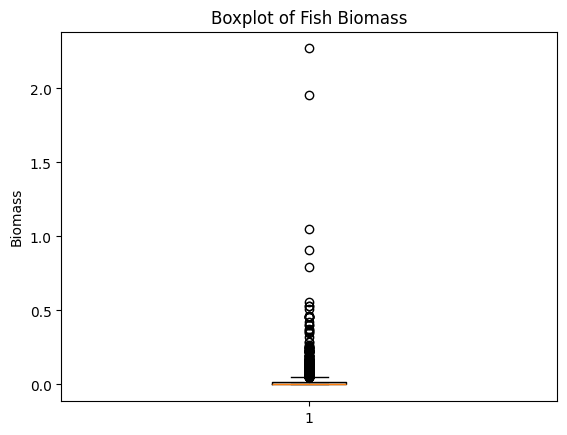

In [ ]:
plt.boxplot(df["biomass"])
plt.ylabel("Biomass")
plt.title("Boxplot of Fish Biomass")
plt.show()

#### The boxplot above shows there are many outliers within the biomass target variable. This shouldn't be an immediate concern and it doesn't mean we should remove them immediately. This could be due to the fact that there are genuinely a lot of large fish in the dataset, a high quantity of fish, or that one species has a greater biomass These outliers will be further analyzed to determine whether or not it will be useful to drop them.

In [ ]:
df.nlargest(10, "biomass")[
    ["species", "quantity", "size", "biomass"]
]

,species,quantity,size,biomass
763,Caranx ruber,50,25,2.2695
757,Caranx ruber,25,30,1.9573
96,Sphyraena barracuda,1,100,1.0517
92,Sphyraena barracuda,4,60,0.9086
2004,Scarus coeruleus,4,40,0.7968
771,Caranx ruber,3,40,0.5551
1957,Pomacanthus paru,2,30,0.5324
1961,Pomacanthus paru,2,30,0.5324
1736,Kyphosus sectatrix,5,30,0.5122
1848,Mycteroperca bonaci,1,60,0.4647


#### According to the table above which shows the largest biomass observations, these are because they are associated with large fish, high cuantities of fish, or both. These observations which caused the skewness represent biological variation rather than data-entry errors which do not need to be handled.

### Investigating relationship between the predictors and biomass (target variable)

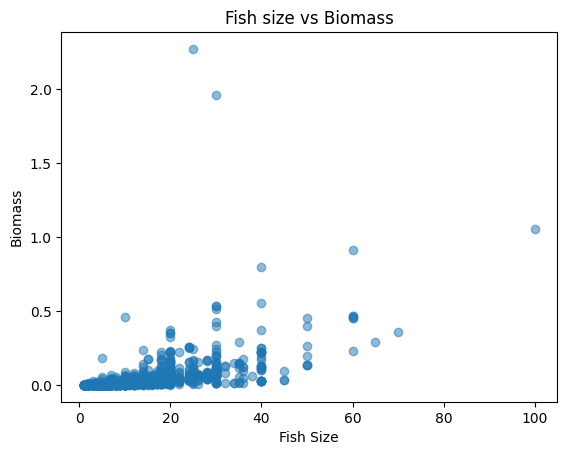

In [ ]:
plt.scatter(df["size"], df["biomass"], alpha=0.5)
plt.xlabel("Fish Size")
plt.ylabel("Biomass")
plt.title("Fish size vs Biomass")
plt.show()

#### The scatterplot above shows how there is a positive relationship between fish size and biomass, larger fish generally have greater biomass. It is important to note that this relationship isn't strictly linear

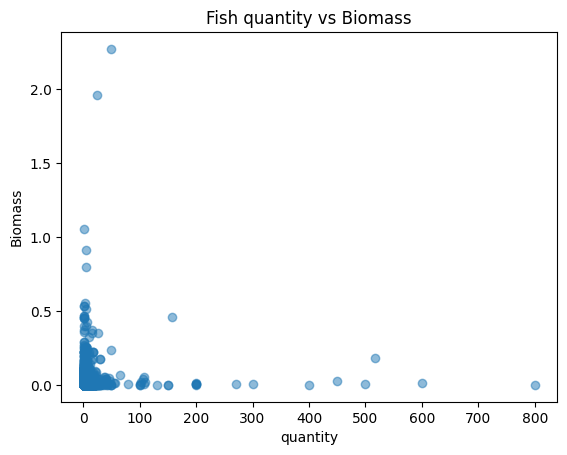

In [ ]:
plt.scatter(df["quantity"], df["biomass"], alpha=0.5)
plt.xlabel("quantity")
plt.ylabel("Biomass")
plt.title("Fish quantity vs Biomass")
plt.show()

#### The plot above doesnt show a strong relationship between fish quantity and biomass. Observations with very high quantittes can still have relatively low biomass, while some observations with lower quantities have much higher biomass. This shows that quantity alone is not enough to predict biomass and that factors such as fish size and species may also be important

In [ ]:
numeric_df = df.select_dtypes(include="number")

numeric_df.corr()["biomass"].sort_values(ascending=False)

,biomass
biomass,1.000000
size,0.523308
trophic_level,0.080825
a_ord,0.078861
transect,0.045028
quantity,0.028104
longitude,0.004785
latitude,-0.001552
id_reef,-0.014219
day,-0.018993


Correlation Analysis: Among the numerical variables, fish size showed the strongest positive correlation with biomass (r = 0.523). The remaining numerical variables had relatively weak linear correlations with biomass. Quantity, for example, had a correlation of only 0.028. Year, month, and area produced undefined correlations because these variables are constant across all observations.

In [ ]:
df.select_dtypes(include="object").nunique().sort_values()

,0
label,1
phylum,1
habitat,1
taxa1,1
taxa2,1
region,2
island,2
side,3
protection_status,3
trophic_group,4


Categorical Feature Analysis: The number of unique categories was examined for each categorical variable. Species had the greatest number of unique categories with 110, followed by family with 28 and reef with 15. Several variables, including label, phylum, habitat, taxa1, and taxa2, contained only one unique value and therefore provide no variation for prediction. These constant features will be removed during preprocessing.

In [ ]:
constant_columns = [col for col in df.columns if df[col].nunique() == 1]
constant_columns

['label', 'year', 'month', 'habitat', 'area', 'phylum', 'taxa1', 'taxa2']

#### the features above contain only 1 unique value. Because these variables have zero variance and cannot contribute to distinguishing biomass values, they were identified for removal before modeling.

In [ ]:
df_clean = df.drop(columns = constant_columns)
df_clean.shape

(2431, 22)

In [ ]:
df_clean.columns

Index(['day', 'region', 'island', 'side', 'id_reef', 'reef', 'reef_joined',
       'protection_status', 'latitude', 'longitude', 'transect', 'taxa3',
       'family', 'trophic_group', 'trophic_level', 'functional_groups',
       'a_ord', 'b_pen', 'species', 'quantity', 'size', 'biomass'],
      dtype='object')

In [ ]:
df_clean = df_clean.drop(columns=["id_reef", "reef_joined"])
df_clean.shape

(2431, 20)

In [ ]:
df_clean[["a_ord", "b_pen", "size", "quantity", "biomass"]].head(10)

,a_ord,b_pen,size,quantity,biomass
0,0.0170,3.120,4,1,0.0002
1,0.0443,2.829,30,1,0.1114
2,0.0443,2.829,30,1,0.1114
3,0.0194,3.000,26,1,0.0568
4,0.0194,3.000,35,1,0.1386
5,0.0194,3.000,20,1,0.0259
6,0.0194,3.000,35,1,0.1386
7,0.0297,2.905,30,1,0.0967
8,0.0297,2.905,20,2,0.0596
9,0.0297,2.905,9,1,0.0029


In [ ]:
df_clean[["a_ord", "b_pen"]].describe()

,a_ord,b_pen
count,2431.000000,2431.000000
mean,0.023805,2.960042
std,0.025825,0.203313
min,0.001000,2.230000
25%,0.014800,2.871000
50%,0.018200,3.000000
75%,0.027700,3.052000
max,0.532000,3.693000


In [ ]:
df_clean = df_clean.drop(columns=["a_ord", "b_pen"])
df_clean.shape

(2431, 18)

#### a_ord and b_pen were removed because they are parameters associated with the fiish length-weight relationship used to estimate biomass. This could lead to target leakage which is why we removed it.

In [ ]:
X = df_clean.drop(columns=["biomass"])
y = df_clean["biomass"]

In [ ]:
print("X shape: ", X.shape)
print("Y shape: ", y.shape)

X shape:  (2431, 19)
Y shape:  (2431,)


#### X - contains the info were going to give the model, such as species, size, quantity, reef characteristics, and other info. Y contains the answer we want the model to predict which is the target varianble. (y = biomass)

### Train/Test split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

In [ ]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1944, 19)
X_test: (487, 19)
y_train: (1944,)
y_test: (487,)


#### The data is divided into 80% training data and 20% testing data and a random state of 42. We chose this split because it makes sense for the size of our dataset. There are approximately 2431 observations so that leaves us with about 487 for training which is a reasonable balance.

In [ ]:
numerical_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(include="object").columns.tolist()

feature_types = pd.DataFrame({
    "Feature": X_train.columns,
    "Type": ["Numerical" if col in numerical_features else "Categorical"
             for col in X_train.columns]
})

feature_types


,Feature,Type
0,day,Numerical
1,region,Categorical
2,island,Categorical
3,side,Categorical
4,reef,Categorical
5,protection_status,Categorical
6,latitude,Numerical
7,longitude,Numerical
8,transect,Numerical
9,taxa3,Categorical


### Preprocessing

In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (1944, 192)
Testing shape: (487, 192)


#### This allows the preprocessing step to learn form the training data, and not from the test data. Doing this prevents data leakage

### PCA

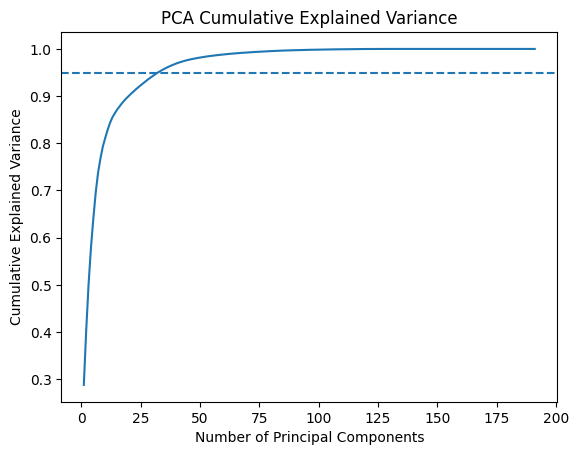

In [ ]:
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

pca = PCA()

X_train_pca = pca.fit_transform(X_train_processed)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance)
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Cumulative Explained Variance")
plt.axhline(y=0.95, linestyle="--")
plt.show()

### Final PCA transformation

In [ ]:
pca_95 = PCA(n_components=34)

X_train_pca = pca_95.fit_transform(X_train_processed)
X_test_pca = pca_95.transform(X_test_processed)

print("PCA training shape:", X_train_pca.shape)
print("PCA testing shape:", X_test_pca.shape)


PCA training shape: (1944, 34)
PCA testing shape: (487, 34)


#### PCA learns the principal components from the training data only. So PCA was fitted only on the training data and then applied to the testing data to prevent data leakage.

### Baseline Model: Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression

lr_original = LinearRegression()
lr_original.fit(X_train_processed, y_train)
y_pred_original = lr_original.predict(X_test_processed)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_original = mean_absolute_error(y_test,y_pred_original)
rmse_original = np.sqrt(mean_squared_error(y_test,y_pred_original))
r2_original = r2_score(y_test, y_pred_original)

print("MAE:", mae_original)
print("RMSE:", rmse_original)
print("R^2:", r2_original)

MAE: 0.023286611667182492
RMSE: 0.050224054603811255
R^2: 0.5335572684382565


The Linear Regression model using the original preprocessed features achieved an MAE of 0.0233, RMSE of 0.0502, and R² of 0.5334. The R² indicates that the model explained approximately 53.3% of the variation in fish biomass in the test data. These results will serve as a baseline for comparison with PCA and other regression models.

### Linear Regression With PCA

In [ ]:
lr_pca = LinearRegression()
lr_pca.fit(X_train_pca, y_train)
y_pred_pca = lr_pca.predict(X_test_pca)

mae_pca = mean_absolute_error(y_test,y_pred_pca)
rmse_pca = np.sqrt(mean_squared_error(y_test,y_pred_pca))
r2_pca = r2_score(y_test, y_pred_pca)

print("PCA MAE:", mae_pca)
print("PCA RMSE:", rmse_pca)
print("PCA R^2:", r2_pca)


PCA MAE: 0.02398264126882334
PCA RMSE: 0.04873151413293516
PCA R^2: 0.5608684911771418


The PCA model also had a slightly lower RMSE, although its MAE was slightly higher. Overall, PCA reduced the number of features from 190 to 34 while maintaining similar predictive performance. This suggests that much of the information contained in the original features can be represented using a smaller number of principal components.

### Random Forest Model

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_original = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_original.fit(X_train_processed, y_train)
y_pred_rf_original = rf_original.predict(X_test_processed)

In [ ]:
mae_rf_original = mean_absolute_error(y_test,y_pred_rf_original)
rmse_rf_original = np.sqrt(mean_squared_error(y_test,y_pred_rf_original))
r2_rf_original = r2_score(y_test, y_pred_rf_original)

print("Random Forest MAE:", mae_rf_original)
print("Random Forest RMSE:", rmse_rf_original)
print("Random Forest R^2:", r2_rf_original)

Random Forest MAE: 0.007362377823408624
Random Forest RMSE: 0.03781864318482171
Random Forest R^2: 0.7355237513263865


#### The Random Forest explained approximately 73.8% of the variation in biomass in the test data and produced lower prediction errors. This suggests that nonlinear relationships and interactions between the predictors may be important for predicting fish biomass.

### Random Forest + PCA

In [ ]:
rf_pca = RandomForestRegressor(
    n_estimators = 100,
    random_state = 42
)

rf_pca.fit(X_train_pca, y_train)
y_pred_rf_pca = rf_pca.predict(X_test_pca)

In [ ]:
mae_rf_pca = mean_absolute_error(y_test,y_pred_rf_pca)
rmse_rf_pca = np.sqrt(mean_squared_error(y_test,y_pred_rf_pca))
r2_rf_pca = r2_score(y_test, y_pred_rf_pca)

print("Random Forest PCA MAE:", mae_rf_pca)
print("Random Forest PCA RMSE:", rmse_rf_pca)
print("Random Forest PCA R^2:", r2_rf_pca)

Random Forest PCA MAE: 0.014108509240246404
Random Forest PCA RMSE: 0.04123252547346472
Random Forest PCA R^2: 0.6856201800774254


#### The PCA model also had higher MAE and RMSE. Therefore, although PCA substantially reduced the number of features, it reduced the predictive performance of the Random Forest model. This suggests that the original features contained useful information and relationships that were better captured directly by Random Forest.

### Gradient Boosting Model

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

gb_original = GradientBoostingRegressor(
    n_estimators=100,
    random_state=42
)

gb_original.fit(X_train_processed, y_train)
y_pred_gb_original = gb_original.predict(X_test_processed)

In [ ]:
mae_gb_original = mean_absolute_error(y_test, y_pred_gb_original)
rmse_gb_original = np.sqrt(mean_squared_error(y_test, y_pred_gb_original))
r2_gb_original = r2_score(y_test, y_pred_gb_original)

print("Gradient Boosting MAE:", mae_gb_original)
print("Gradient Boosting RMSE:", rmse_gb_original)
print("Gradient Boosting R^2:", r2_gb_original)


Gradient Boosting MAE: 0.007990452842332536
Gradient Boosting RMSE: 0.03609901820919403
Gradient Boosting R^2: 0.7590285616703379


#### The Gradient Boosting model achieved an MAE of 0.0094, RMSE of 0.0375, and R² of 0.7395. This means the model explained approximately 73.9% of the variation in biomass in the test data. Its performance was very similar to Random Forest. These results suggest that nonlinear tree-based models are better able to capture relationships between the predictors and fish biomass.

#### Gradient Boosting with PCA

In [ ]:
gb_pca = GradientBoostingRegressor(
    n_estimators=100,
    random_state=42
)

gb_pca.fit(X_train_pca, y_train)

y_pred_gb_pca = gb_pca.predict(X_test_pca)

mae_gb_pca = mean_absolute_error(y_test, y_pred_gb_pca)
rmse_gb_pca = np.sqrt(mean_squared_error(y_test, y_pred_gb_pca))
r2_gb_pca = r2_score(y_test, y_pred_gb_pca)

print("Gradient Boosting PCA MAE:", mae_gb_pca)
print("Gradient Boosting PCA RMSE:", rmse_gb_pca)
print("Gradient Boosting PCA R^2:", r2_gb_pca)

Gradient Boosting PCA MAE: 0.016299845816774548
Gradient Boosting PCA RMSE: 0.045647174467585885
Gradient Boosting PCA R^2: 0.6146968236850017


#### PCA significantly reduced gradient boosting's predictive performance. The R^2 dropped from 73.9% to 49.5%. This means the principal components were less effective for this model than the original features it had.

### XGBoost Model

In [ ]:
from xgboost import XGBRegressor

xgb_original = XGBRegressor(
    n_estimators=100,
    random_state=42
)

xgb_original.fit(X_train_processed, y_train)
y_pred_xgb_original = xgb_original.predict(X_test_processed)

In [ ]:
mae_xgb_original = mean_absolute_error(y_test, y_pred_xgb_original)
rmse_xgb_original = np.sqrt(mean_squared_error(y_test, y_pred_xgb_original))
r2_xgb_original = r2_score(y_test, y_pred_xgb_original)

print("XGBoost MAE:", mae_xgb_original)
print("XGBoost RMSE:", rmse_xgb_original)
print("XGBoost R^2:", r2_xgb_original)

XGBoost MAE: 0.006116788872705009
XGBoost RMSE: 0.03525832321759959
XGBoost R^2: 0.7701216356716104


#### The XGBoost model achieved an MAE of 0.0066, RMSE of 0.0359, and R² of 0.7613. This means the model explained approximately 76.1% of the variation in fish biomass in the test data. XGBoost performed better than the previously tested models based on these three evaluation metrics.

### XGBoost PCA

In [ ]:
xgb_pca = XGBRegressor(
    n_estimators=100,
    random_state=42
)

xgb_pca.fit(X_train_pca, y_train)

y_pred_xgb_pca = xgb_pca.predict(X_test_pca)

mae_xgb_pca = mean_absolute_error(y_test, y_pred_xgb_pca)
rmse_xgb_pca = np.sqrt(mean_squared_error(y_test, y_pred_xgb_pca))
r2_xgb_pca = r2_score(y_test, y_pred_xgb_pca)

print("XGBoost PCA MAE:", mae_xgb_pca)
print("XGBoost  PCA RMSE:", rmse_xgb_pca)
print("XGBoost PCA R^2:", r2_xgb_pca)

XGBoost PCA MAE: 0.016873674943632438
XGBoost  PCA RMSE: 0.08125702121041528
XGBoost PCA R^2: -0.22094635880660896


#### XGBoost without PCA achieved an R² of 0.7613, while XGBoost with PCA achieved an R² of 0.2894. The PCA model also had higher MAE and RMSE. Therefore, PCA substantially reduced the predictive performance of XGBoost. Although PCA reduced the number of features, the original processed features were more useful for predicting biomass with XGBoost.

### Model Comparison

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Linear Regression + PCA",
        "Random Forest",
        "Random Forest + PCA",
        "Gradient Boosting",
        "Gradient Boosting + PCA",
        "XGBoost",
        "XGBoost + PCA"
    ],

    "MAE": [
        mae_original,
        mae_pca,
        mae_rf_original,
        mae_rf_pca,
        mae_gb_original,
        mae_gb_pca,
        mae_xgb_original,
        mae_xgb_pca
    ],

    "RMSE": [
        rmse_original,
        rmse_pca,
        rmse_rf_original,
        rmse_rf_pca,
        rmse_gb_original,
        rmse_gb_pca,
        rmse_xgb_original,
        rmse_xgb_pca
    ],

    "R2": [
        r2_original,
        r2_pca,
        r2_rf_original,
        r2_rf_pca,
        r2_gb_original,
        r2_gb_pca,
        r2_xgb_original,
        r2_xgb_pca
    ]
})

results.round(4)

,Model,MAE,RMSE,R2
0,Linear Regression,0.0233,0.0502,0.5336
1,Linear Regression + PCA,0.0240,0.0487,0.5609
2,Random Forest,0.0074,0.0378,0.7355
3,Random Forest + PCA,0.0141,0.0412,0.6856
4,Gradient Boosting,0.0080,0.0361,0.7590
5,Gradient Boosting + PCA,0.0163,0.0456,0.6147
6,XGBoost,0.0061,0.0353,0.7701
7,XGBoost + PCA,0.0169,0.0813,-0.2209


### Model comparison graph: R^2

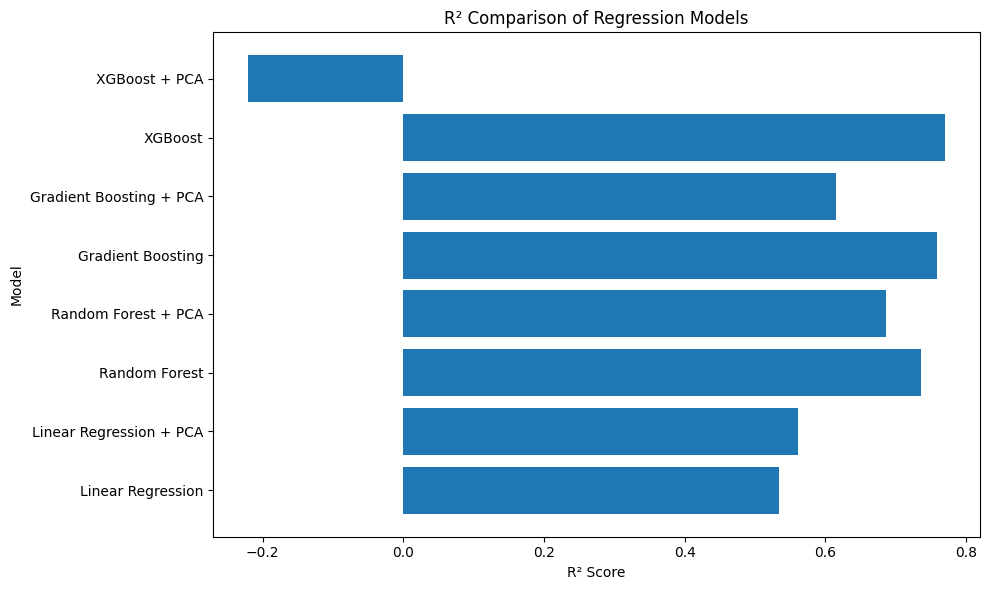

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(results["Model"], results["R2"])

plt.xlabel("R² Score")
plt.ylabel("Model")
plt.title("R² Comparison of Regression Models")

plt.tight_layout()
plt.show()

#### The tree-based models without PCA generally achieved higher R² scores than Linear Regression. XGBoost achieved the highest R² of 0.7613. PCA slightly improved Linear Regression but reduced the performance of Random Forest, Gradient Boosting, and XGBoost. This suggests that PCA was less beneficial for the tree-based models.

### RMSE graph

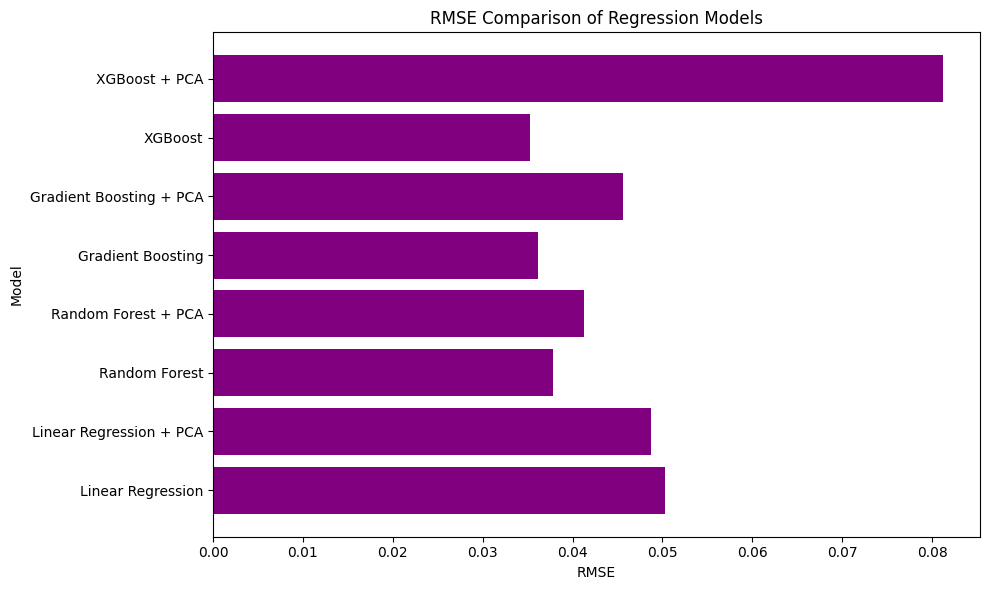

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(results["Model"], results["RMSE"], color="purple")

plt.xlabel("RMSE")
plt.ylabel("Model")
plt.title("RMSE Comparison of Regression Models")

plt.tight_layout()
plt.show()

#### XGBoost without PCA achieved the lowest RMSE of 0.0359, indicating the lowest prediction error among the models tested. Random Forest and Gradient Boosting without PCA also performed well. PCA generally increased the prediction error of the tree-based models, with XGBoost + PCA producing the highest RMSE.

### Random Forest 5-fold Cross-Validation

In [ ]:
from sklearn.model_selection import cross_val_score

rf_cv_scores = cross_val_score(
    rf_original,
    X_train_processed,
    y_train,
    cv=5,
    scoring="r2"
)

print("Random Forest R² scores:", rf_cv_scores)
print("Mean R²:", rf_cv_scores.mean())
print("Standard Deviation:", rf_cv_scores.std())

Random Forest R² scores: [0.81616026 0.63787672 0.81470828 0.85436595 0.37761378]
Mean R²: 0.7001449971156932
Standard Deviation: 0.17791690020634549


#### The Random Forest model achieved a mean 5-fold cross-validation R² of 0.6905 with a standard deviation of 0.1612. Performance varied across the five folds, with R² scores ranging from approximately 0.4000 to 0.8226. This suggests that Random Forest generally performs well but its performance varies across different subsets of the training data.

### Gradient Boosting 5 fold cross validation

In [ ]:
gb_cv_scores = cross_val_score(
    gb_original,
    X_train_processed,
    y_train,
    cv=5,
    scoring="r2"
)

print("Gradient Boosting R² scores:", gb_cv_scores)
print("Mean R²:", gb_cv_scores.mean())
print("Standard Deviation:", gb_cv_scores.std())

Gradient Boosting R² scores: [0.75719316 0.5975383  0.93476478 0.79214855 0.7289083 ]
Mean R²: 0.7621106159161893
Standard Deviation: 0.10855630663545288


#### Gradient Boosting achieved a mean 5-fold cross-validation R² of 0.7776 with a standard deviation of 0.1015. The individual R² scores ranged from approximately 0.6745 to 0.9460. Compared with Random Forest, Gradient Boosting produced a higher average R² and showed less variation across the five folds.

### XGBoost 5-fold CV

In [ ]:
xgb_cv_scores = cross_val_score(
    xgb_original,
    X_train_processed,
    y_train,
    cv=5,
    scoring="r2"
)

print("XGBoost R² scores:", xgb_cv_scores)
print("Mean R²:", xgb_cv_scores.mean())
print("Standard Deviation:", xgb_cv_scores.std())

XGBoost R² scores: [0.84259737 0.92662687 0.84296369 0.88006033 0.54351277]
Mean R²: 0.8071522070523441
Standard Deviation: 0.13537678312603962


#### XGBoost achieved a mean 5-fold cross-validation R² of 0.8082 with a standard deviation of 0.1310. The individual R² scores ranged from approximately 0.5523 to 0.9202. XGBoost had the highest mean cross-validation R² among the three models tested, although some variation was observed across the folds. single test split showed XGBoost at \(R^2=0.7613\), and the 5-fold CV average was \(0.8082\). So its strong performance wasn't limited to that one test split.

#### CV Comparison Graph

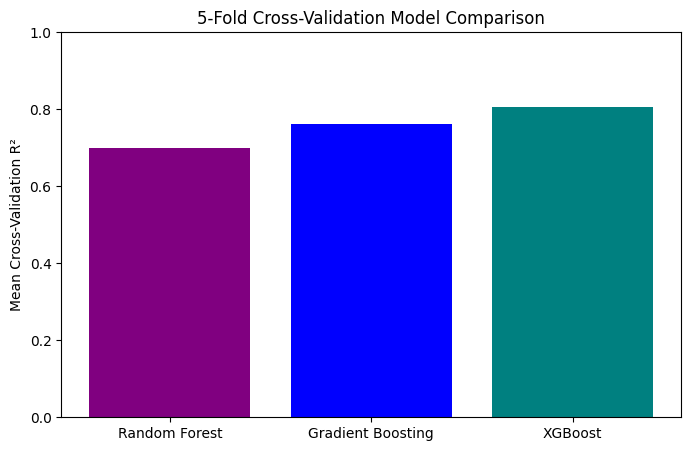

In [ ]:
cv_models = ["Random Forest", "Gradient Boosting", "XGBoost"]

cv_mean_scores = [
    rf_cv_scores.mean(),
    gb_cv_scores.mean(),
    xgb_cv_scores.mean()
]

plt.figure(figsize=(8, 5))

plt.bar(
    cv_models,
    cv_mean_scores,
    color=["purple", "blue", "teal"]
)

plt.ylabel("Mean Cross-Validation R²")
plt.title("5-Fold Cross-Validation Model Comparison")
plt.ylim(0, 1)

plt.show()

#### XGBoost achieved the highest mean 5-fold cross-validation R² of 0.8082, followed by Gradient Boosting at 0.7776 and Random Forest at 0.6905. These results show that the stronger model performances were observed across multiple training and validation splits rather than only a single split.

### Baseline Model

In [ ]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train_processed, y_train)
y_pred_baseline = baseline.predict(X_test_processed)

baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
baseline_r2 = r2_score(y_test, y_pred_baseline)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R^2:", baseline_r2)

Baseline MAE: 0.0334394154392814
Baseline RMSE: 0.07354437641698458
Baseline R^2: -0.00016978125374778053


#### A mean Dummy Regressor was used as a simple baseline for comparison. The baseline produced an MAE of 0.0334, RMSE of 0.0735, and an R² close to 0. The machine learning models produced lower prediction errors and higher R² values than the baseline, showing that they learned useful patterns for predicting fish biomass.

### Hyperparameter tuning for XGBoost

In [ ]:
param_grid = {
    "n_estimators": [50, 100, 150, 200, 250],
    "max_depth": [2, 3, 4, 5, 6]
}

In [ ]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

xgb_grid = GridSearchCV(
    estimator=XGBRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    return_train_score=True
)

In [ ]:
xgb_grid.fit(X_train_processed, y_train)

GridSearchCV(cv=5,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=True, eval_metric=None,
                                    feature_types=None, feature_weights=None,
                                    gamma=None, grow_policy=None,
                                    importance_type=None,
                                    interaction_constraints=None,
                                    learning_rate=None, max_bin=None,
                                    max_cat_threshold=None,
                                    max_cat_to_onehot=None, max_delta_step=None,
                                    max_depth=None, max_leaves=None,
                                    min_child_weight=None, missing=nan,
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=None, num_parallel_tree=None, ...),
             param_grid={'max_depth': [2, 3, 4, 5, 6],
                         'n_estimators': [50, 100, 150, 200, 250]},
             return_train_score=True, scoring='r2')

In [ ]:
print("Best parameters:", xgb_grid.best_params_)
print("Best cross-validation R²:", xgb_grid.best_score_)

Best parameters: {'max_depth': 2, 'n_estimators': 250}
Best cross-validation R²: 0.8751832981078188


In [ ]:
best_xgb = xgb_grid.best_estimator_

In [ ]:
y_pred_tuned = best_xgb.predict(X_test_processed)

mae_xgb_tuned = mean_absolute_error(y_test, y_pred_tuned)
rmse_xgb_tuned = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
r2_xgb_tuned = r2_score(y_test, y_pred_tuned)

print("Tuned XGBoost MAE:", mae_xgb_tuned)
print("Tuned XGBoost RMSE:", rmse_xgb_tuned)
print("Tuned XGBoost R²:", r2_xgb_tuned)

Tuned XGBoost MAE: 0.009768166236145168
Tuned XGBoost RMSE: 0.04099384537433657
Tuned XGBoost R²: 0.6892493066984273


#### GridSearchCV with 5-fold cross-validation was used to tune the number of estimators and maximum tree depth. The best parameters were n_estimators = 250 and max_depth = 2, with a mean cross-validation R² of 0.8652. However, when evaluated on the test set, the tuned model achieved an R² of 0.7016, compared with 0.7613 for the original XGBoost model. The tuned model also had higher MAE and RMSE. Therefore, although tuning improved cross-validation performance, it did not improve performance on the held-out test set.

### GridSearch CV results

In [ ]:
grid_results = pd.DataFrame(xgb_grid.cv_results_)

tuning_table = grid_results[[
    "param_n_estimators",
    "param_max_depth",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]]

tuning_table = tuning_table.sort_values("rank_test_score")

tuning_table.head(10)

,param_n_estimators,param_max_depth,mean_train_score,mean_test_score,std_test_score,rank_test_score
4,250,2,0.993730,0.875183,0.059724,1
3,200,2,0.991972,0.871688,0.059676,2
9,250,3,0.998970,0.867136,0.078876,3
8,200,3,0.998501,0.866000,0.078806,4
2,150,2,0.989442,0.865720,0.059484,5
7,150,3,0.997844,0.864471,0.078603,6
6,100,3,0.996164,0.861168,0.078096,7
1,100,2,0.983712,0.851048,0.063805,8
5,50,3,0.991716,0.846230,0.076758,9
14,250,4,0.999702,0.840924,0.084881,10


### Feature Importance: Which predictors were most important?

In [ ]:
feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(feature_names))
print(feature_names[:20])

Number of features: 192
['num__day' 'num__latitude' 'num__longitude' 'num__transect'
 'num__trophic_level' 'num__a_ord' 'num__b_pen' 'num__quantity'
 'num__size' 'cat__region_Alacranes' 'cat__region_Bajo del Norte'
 'cat__island_Arrecife Alacranes' 'cat__island_Bajos del Norte'
 'cat__side_Bajos' 'cat__side_Leeward' 'cat__side_Windward'
 'cat__reef_Alacranes 7' 'cat__reef_Arcos' 'cat__reef_Bajos del norte'
 'cat__reef_Bajos del norte 2']


In [ ]:
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_original.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
42,cat__family_Carangidae,0.387964
7,num__quantity,0.216893
8,num__size,0.084129
163,cat__species_Pomacanthus paru,0.061033
44,cat__family_Diodontidae,0.037243
35,cat__taxa3_Perciformes,0.034296
67,cat__trophic_group_Carnivore,0.030696
63,cat__family_Serranidae,0.018792
36,cat__taxa3_Syngnathiformes,0.015803
5,num__a_ord,0.012482


In [ ]:
grouped_importance = {}

for col in numerical_features:
    grouped_importance[col] = feature_importance.loc[
        feature_importance["Feature"] == "num__" + col,
        "Importance"
    ].sum()

for col in categorical_features:
    grouped_importance[col] = feature_importance.loc[
        feature_importance["Feature"].str.startswith("cat__" + col + "_"),
        "Importance"
    ].sum()

grouped_importance = pd.Series(grouped_importance).sort_values(
    ascending=False
)

grouped_importance

,0
family,0.455055
quantity,0.216893
species,0.095414
size,0.084129
taxa3,0.052769
trophic_group,0.030747
functional_groups,0.021931
a_ord,0.012482
b_pen,0.010359
reef,0.007898


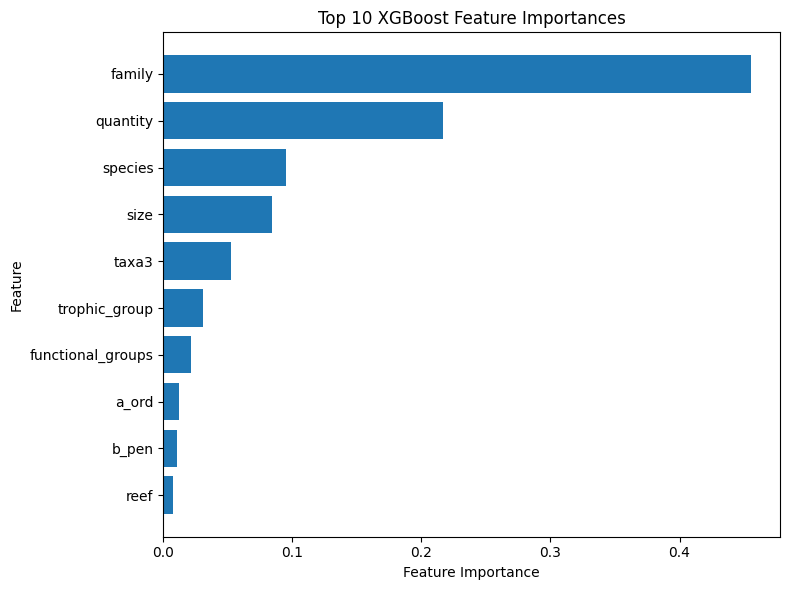

In [ ]:
top_features = grouped_importance.head(10)

plt.figure(figsize=(8, 6))
plt.barh(top_features.index[::-1], top_features.values[::-1])

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 XGBoost Feature Importances")

plt.tight_layout()
plt.show()

#### XGBoost feature importance was used to examine which predictors contributed most to biomass prediction. The categorical variables were grouped back into their original features after one-hot encoding. Family had the highest grouped importance (0.4329), followed by quantity (0.1849), taxonomic group (0.1115), species (0.0960), and size (0.0801). These results suggest that taxonomic characteristics and fish abundance and size were important to the model's biomass predictions. Feature importance describes how the model used the predictors and should not be interpreted as a causal relationship.

### Results

#### The models showed that fish biomass can be predicted using the available biological and environmental features. Among the original models, XGBoost produced the strongest test performance with an R² of 0.7613, MAE of 0.0066, and RMSE of 0.0359. Random Forest and Gradient Boosting also performed well, while Linear Regression had lower predictive performance. PCA reduced the number of features from 190 to 34, but it generally reduced the performance of the tree-based models. The baseline model performed substantially worse than the machine learning models, showing that the models learned useful patterns in the data.

### Limitations

#### One limitation of this project is that biomass is highly skewed, with many small values and a few very large values. These extreme observations can make prediction more difficult and can have a larger effect on error measures such as RMSE. Model performance also varied across the cross-validation folds, showing that results can depend on which observations are used for training and validation. In addition, XGBoost feature importance shows which variables the model relied on for prediction, but it does not prove that those variables cause changes in biomass. Finally, some categorical variables, especially species, contain many categories, which increased the number of features after one-hot encoding.

### Future Work

#### Future work could explore more advanced machine learning methods, such as neural networks, to determine whether they improve biomass prediction. Additional hyperparameter tuning could also be performed for models such as XGBoost, Random Forest, and Gradient Boosting.

### Conclusion

#### This project examined whether fish biomass could be predicted using biological and environmental characteristics and which features were most important for prediction. Among the models tested, the original XGBoost model produced the strongest test performance, with an R² of 0.7613, MAE of 0.0066, and RMSE of 0.0359. XGBoost feature importance showed that family, quantity, taxonomic group, species, and size were among the most important predictors used by the model. PCA reduced the number of features but generally did not improve the tree-based models. Overall, the results show that machine learning can identify useful patterns for predicting fish biomass, although additional data and more advanced modeling could be explored in future work.